# JS06 — Praktikum 1
## Perbandingan Exact Nearest Neighbor (ENN) dan Approximate Nearest Neighbor (Annoy)

**Tujuan:** Membandingkan indeks terdekat, waktu pencarian, dan kualitas *approximate nearest neighbor* untuk variasi jumlah *tree*, jumlah data, serta metrik Euclidean/Angular. Mencakup simulasi rekomendasi lagu 20 fitur dengan **1.000.000 track**.

**Cara menjalankan:** Buka di Google Colab → **Runtime → Run all**. Dataset dibangkitkan otomatis dengan seed tetap; tidak perlu mengunggah CSV. Waktu komputasi bergantung pada perangkat. Pembuatan indeks 1 juta track memerlukan waktu dan memori yang relatif besar.

> **Catatan ketentuan:** Pada contoh modul tercantum `n_tracks = 50_000_000`, tetapi tabel tugas secara eksplisit meminta **1.000.000**; notebook menggunakan 1 juta sesuai tabel. Index Annoy dicari menggunakan `get_nns_by_vector` dengan `search_k=-1` (default), sehingga hasil dapat tidak sama persis dengan Exact NN. Angka-angka dicetak langsung dari eksekusi, bukan disalin dari contoh.

### 0. Instalasi dan import library
Instal `annoy` satu kali pada runtime Google Colab. Jika `annoy` sudah terpasang, perintah ini dapat dilewati.

In [1]:
%pip -q install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 11.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [2]:
import os
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from annoy import AnnoyIndex
from IPython.display import display

print("Annoy dan library pendukung berhasil diimpor.")

Annoy dan library pendukung berhasil diimpor.


### 1. Fungsi Exact NN dan evaluasi

- **Euclidean:** $d(x,q)=\sqrt{\sum_j(x_j-q_j)^2}$.
- **Angular (Annoy):** $d(x,q)=\sqrt{2(1-\cos(x,q))}$, dengan $\cos(x,q)=\frac{x\cdot q}{\|x\|\|q\|}$.
- Untuk tiap baris, *Exact NN* dan Annoy memakai **data dan query yang sama**, **metrik yang sama**, dan jumlah tetangga sama.
- **Recall@k** mengukur proporsi indeks Exact NN yang berhasil ditemukan oleh Annoy, tanpa memperhatikan urutan.
- Pengukuran memakai `time.perf_counter()`; angka waktu yang disajikan adalah **median** beberapa panggilan (pada 1 juta data, Exact NN hanya satu kali untuk menjaga durasi).
- Pemrosesan Exact NN dilakukan bertahap (*chunking*) agar tidak membengkakkan RAM pada data besar; ia tetap memeriksa **seluruh baris**, sehingga hasilnya eksak.

In [3]:
def exact_knn(data, query, k=3, metric="euclidean", chunk_size=100_000):
    """Brute-force exact k-NN, mengevaluasi semua titik dengan RAM terbatas."""
    query64 = np.asarray(query, dtype=np.float64)
    q_norm = np.linalg.norm(query64)
    best_dist = np.full(k, np.inf, dtype=np.float64)
    best_index = np.full(k, -1, dtype=np.int64)

    for start in range(0, len(data), chunk_size):
        chunk = data[start:start + chunk_size].astype(np.float64, copy=False)
        if metric == "euclidean":
            delta = chunk - query64
            distances = np.sqrt(np.einsum("ij,ij->i", delta, delta))
        elif metric == "angular":
            norms = np.linalg.norm(chunk, axis=1)
            similarity = (chunk @ query64) / np.maximum(norms * q_norm, 1e-15)
            distances = np.sqrt(2.0 * (1.0 - np.clip(similarity, -1, 1)))
        else:
            raise ValueError("metric harus 'euclidean' atau 'angular'")

        local_k = min(k, len(distances))
        local_ids = np.argpartition(distances, local_k - 1)[:local_k]
        indices = np.concatenate((best_index, start + local_ids))
        values = np.concatenate((best_dist, distances[local_ids]))
        order = np.lexsort((indices, values))[:k]
        best_index, best_dist = indices[order], values[order]

    return best_index.tolist(), best_dist.tolist()


def benchmark_exact(data, query, k, metric, repeats):
    # Warm-up dipisah dari pengukuran untuk mengurangi efek run pertama
    idx, dist = exact_knn(data, query, k, metric)
    timings = []
    for _ in range(repeats):
        tic = time.perf_counter()
        idx, dist = exact_knn(data, query, k, metric)
        timings.append((time.perf_counter() - tic) * 1000)
    return idx, dist, float(np.median(timings))


def benchmark_annoy(data, query, k, metric, n_trees, repeats=30, seed=42):
    """Build dilakukan sekali; waktu penambahan item/build dan waktu lookup dicatat terpisah."""
    index = AnnoyIndex(data.shape[1], metric)
    index.set_seed(seed)

    tic = time.perf_counter()
    for i, vec in enumerate(data):
        index.add_item(i, vec)
    add_seconds = time.perf_counter() - tic

    tic = time.perf_counter()
    index.build(n_trees, n_jobs=2)
    build_seconds = time.perf_counter() - tic

    index.get_nns_by_vector(query, k)  # warm-up
    lookup_times = []
    indices = []
    for _ in range(repeats):
        tic = time.perf_counter()
        indices = index.get_nns_by_vector(query, k)
        lookup_times.append((time.perf_counter() - tic) * 1000)

    return indices, float(np.median(lookup_times)), add_seconds, build_seconds


def recall_at_k(exact_ids, approx_ids):
    return len(set(exact_ids) & set(approx_ids)) / len(exact_ids)


def make_data_2d(n, seed=42):
    # Samakan generator dengan contoh praktikum; n berbeda = dataset berbeda
    rng = np.random.RandomState(seed)
    points = (rng.rand(n, 2) * 100).astype(np.float32)
    query_index = int(rng.randint(0, n))
    return points, points[query_index].copy(), query_index


# Uji singkat ketepatan fungsi pencarian eksak
sample = np.array([[0, 0], [1, 0], [2, 0], [4, 0]], dtype=np.float32)
assert exact_knn(sample, np.array([0, 0]), k=3)[0] == [0, 1, 2]
print("Fungsi Exact NN siap dipakai.")

Fungsi Exact NN siap dipakai.


### 2. Eksperimen 2D — enam kombinasi

Setiap hasil berisi indeks 3 titik terdekat, perbandingan waktu lookup (ms), waktu penambahan data, dan waktu pembangunan indeks Annoy (detik). Eksperimen `tree=3` dan `tree=8` pada jumlah data sama menggunakan titik serta query yang sama. Karena query berasal dari dataset, salah satu tetangga adalah titik itu sendiri.

In [4]:
K_NEIGHBORS = 3
CASES_2D = [
    ("euclidean", 3, 1_000),
    ("euclidean", 8, 1_000),
    ("euclidean", 3, 100_000),
    ("angular", 3, 1_000),
    ("angular", 8, 1_000),
    ("angular", 3, 100_000),
]

results_2d = []
exact_cache = {}

for metric, trees, n in CASES_2D:
    X, query, query_id = make_data_2d(n)
    key = (metric, n)

    if key not in exact_cache:
        exact_cache[key] = benchmark_exact(
            X, query, K_NEIGHBORS, metric,
            repeats=7 if n == 1_000 else 3
        )

    exact_ids, exact_dist, t_exact = exact_cache[key]
    approx_ids, t_ann, t_add, t_build = benchmark_annoy(
        X, query, K_NEIGHBORS, metric, trees, repeats=50
    )

    row = {
        "Distance Metrics": metric.capitalize(),
        "Tree": trees,
        "Jumlah data": n,
        "Query index": query_id,
        "Exact NN index": str(exact_ids),
        "Annoy NN index": str(approx_ids),
        "Recall@3": recall_at_k(exact_ids, approx_ids),
        "Waktu Exact (ms)": t_exact,
        "Waktu Annoy (ms)": t_ann,
        "Percepatan (x)": t_exact / t_ann if t_ann else np.nan,
        "Tambah item (s)": t_add,
        "Build index (s)": t_build,
    }
    results_2d.append(row)
    print(f"Selesai: {metric:9s} | trees={trees} | n={n:,} | "
          f"Recall@3={row['Recall@3']:.0%} | "
          f"Exact={t_exact:.4f} ms | Annoy={t_ann:.4f} ms")
    del X, query
    gc.collect()

df_2d = pd.DataFrame(results_2d)
print("\n=== TABEL 1 — HASIL PERCOBAAN 2D ===")
display(df_2d[[
    "Distance Metrics", "Tree", "Jumlah data", "Exact NN index", "Annoy NN index",
    "Waktu Exact (ms)", "Waktu Annoy (ms)", "Recall@3", "Build index (s)"
]].round(4))

Selesai: euclidean | trees=3 | n=1,000 | Recall@3=100% | Exact=0.1213 ms | Annoy=0.0048 ms
Selesai: euclidean | trees=8 | n=1,000 | Recall@3=100% | Exact=0.1213 ms | Annoy=0.0091 ms
Selesai: euclidean | trees=3 | n=100,000 | Recall@3=100% | Exact=6.6012 ms | Annoy=0.0057 ms
Selesai: angular   | trees=3 | n=1,000 | Recall@3=100% | Exact=0.1633 ms | Annoy=0.0047 ms
Selesai: angular   | trees=8 | n=1,000 | Recall@3=100% | Exact=0.1633 ms | Annoy=0.0078 ms
Selesai: angular   | trees=3 | n=100,000 | Recall@3=100% | Exact=3.6935 ms | Annoy=0.0074 ms

=== TABEL 1 — HASIL PERCOBAAN 2D ===


,Distance Metrics,Tree,Jumlah data,Exact NN index,Annoy NN index,Waktu Exact (ms),Waktu Annoy (ms),Recall@3,Build index (s)
0,Euclidean,3,1000,"[219, 898, 593]","[219, 898, 593]",0.1213,0.0048,1.0,0.0114
1,Euclidean,8,1000,"[219, 898, 593]","[219, 898, 593]",0.1213,0.0091,1.0,0.0304
2,Euclidean,3,100000,"[64040, 64186, 88792]","[64040, 64186, 88792]",6.6012,0.0057,1.0,0.9378
3,Angular,3,1000,"[219, 429, 540]","[219, 429, 540]",0.1633,0.0047,1.0,0.0222
4,Angular,8,1000,"[219, 429, 540]","[219, 429, 540]",0.1633,0.0078,1.0,0.0461
5,Angular,3,100000,"[64040, 1310, 1267]","[64040, 1267, 1310]",3.6935,0.0074,1.0,5.4500


### 3. Visualisasi Exact NN versus Annoy

Biru = Exact NN, hijau = Annoy, merah = query. Jika titik biru dan hijau bertumpuk, kedua algoritma memilih indeks yang sama.

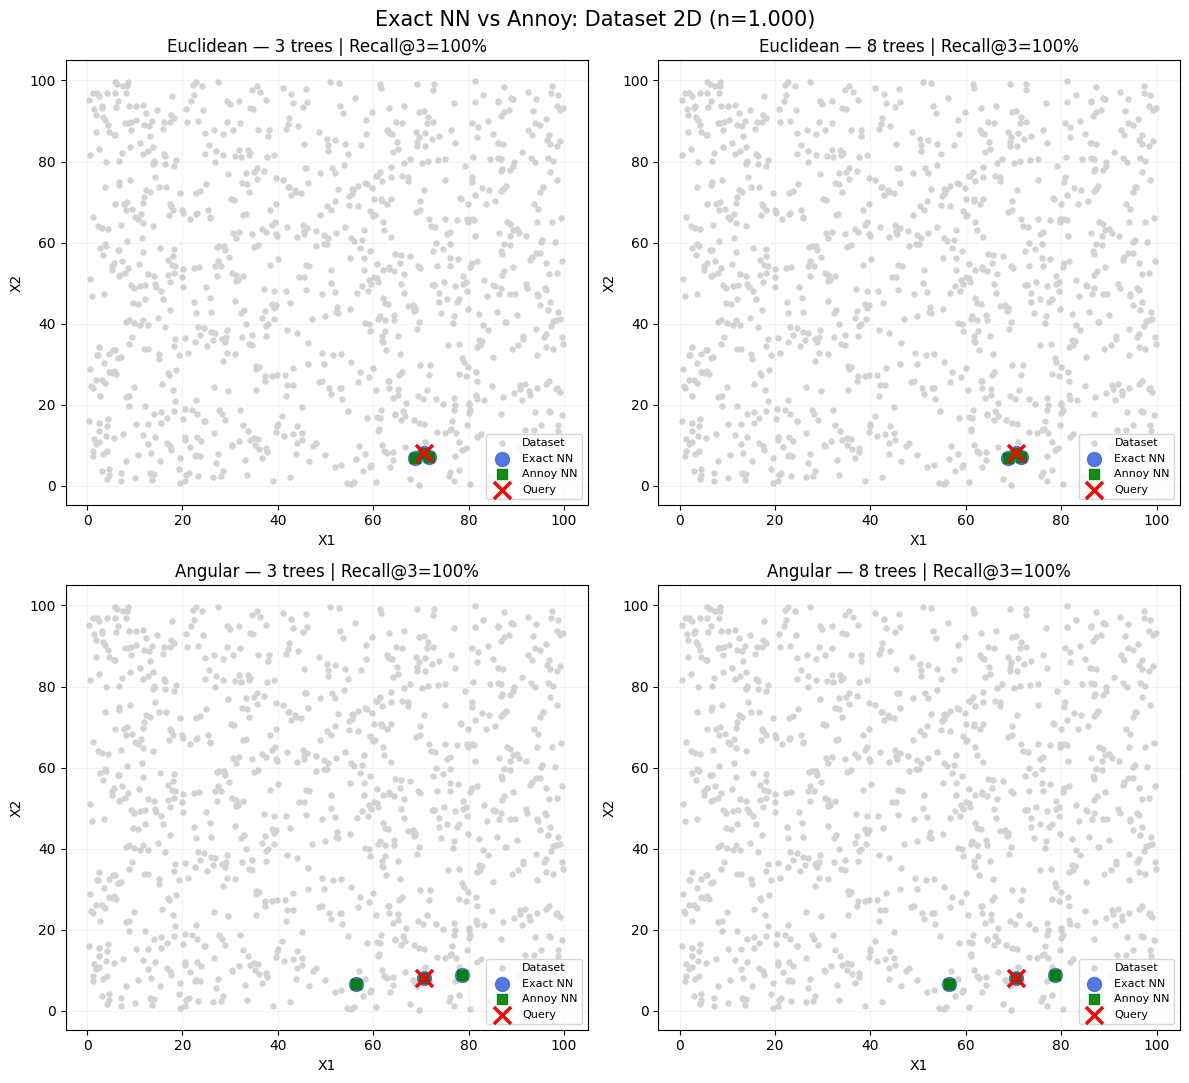

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, metric, trees in zip(axes.flat,
                             ["euclidean", "euclidean", "angular", "angular"],
                             [3, 8, 3, 8]):
    X, query, _ = make_data_2d(1_000)
    exact_ids, _ = exact_knn(X, query, k=3, metric=metric)
    # Untuk visualisasi dibangun kembali dari data 1000; tidak memengaruhi tabel benchmark.
    ix = AnnoyIndex(2, metric)
    ix.set_seed(42)
    for i, p in enumerate(X):
        ix.add_item(i, p)
    ix.build(trees, n_jobs=2)
    ann_ids = ix.get_nns_by_vector(query, 3)

    ax.scatter(X[:, 0], X[:, 1], color="lightgray", s=13, label="Dataset")
    ax.scatter(X[exact_ids, 0], X[exact_ids, 1], color="royalblue",
               s=100, alpha=0.9, label="Exact NN")
    ax.scatter(X[ann_ids, 0], X[ann_ids, 1], color="green",
               marker="s", s=42, alpha=0.9, label="Annoy NN")
    ax.scatter(query[0], query[1], color="red", marker="x", s=150,
               linewidths=2.5, label="Query")
    ax.set_title(f"{metric.capitalize()} — {trees} trees | Recall@3="
                 f"{recall_at_k(exact_ids, ann_ids):.0%}")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

plt.suptitle("Exact NN vs Annoy: Dataset 2D (n=1.000)", fontsize=15)
plt.tight_layout()
plt.show()

### 4. Grafik waktu lookup dan analisis 2D

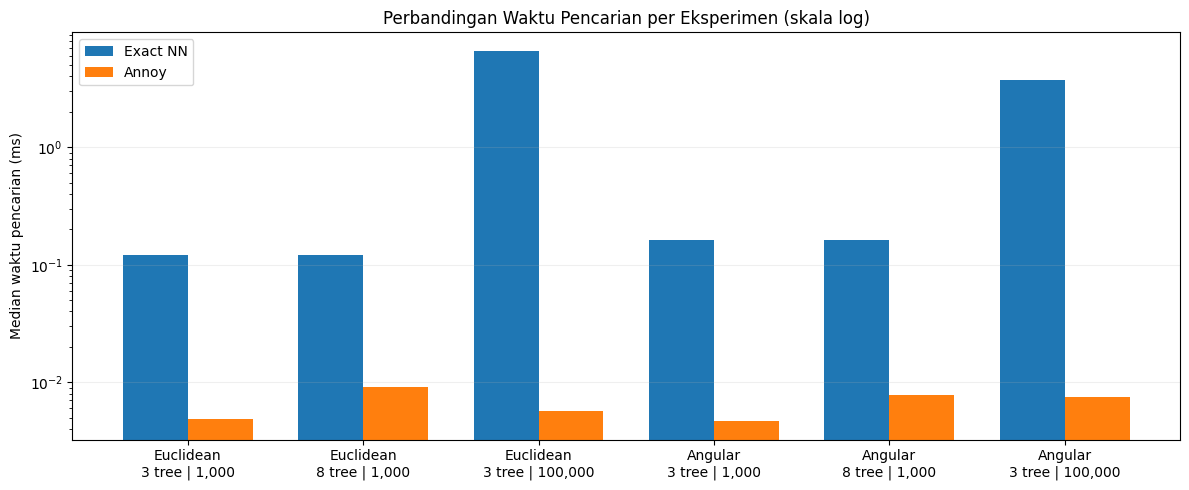

=== ANALISIS OTOMATIS PERCOBAAN 2D ===
Euclidean, 3 tree, n=1,000: Recall@3=100.0% (semua indeks cocok); percepatan lookup=25.12x; build index=0.011 detik.
Euclidean, 8 tree, n=1,000: Recall@3=100.0% (semua indeks cocok); percepatan lookup=13.31x; build index=0.030 detik.
Euclidean, 3 tree, n=100,000: Recall@3=100.0% (semua indeks cocok); percepatan lookup=1149.23x; build index=0.938 detik.
Angular, 3 tree, n=1,000: Recall@3=100.0% (semua indeks cocok); percepatan lookup=34.93x; build index=0.022 detik.
Angular, 8 tree, n=1,000: Recall@3=100.0% (semua indeks cocok); percepatan lookup=21.02x; build index=0.046 detik.
Angular, 3 tree, n=100,000: Recall@3=100.0% (semua indeks cocok); percepatan lookup=497.71x; build index=5.450 detik.


In [6]:
labels_plot = [f"{r['Distance Metrics']}\n{r['Tree']} tree | {r['Jumlah data']:,}"
               for _, r in df_2d.iterrows()]
positions = np.arange(len(df_2d))
fig, ax = plt.subplots(figsize=(12, 5))
w = 0.37
ax.bar(positions - w/2, df_2d["Waktu Exact (ms)"], width=w, label="Exact NN")
ax.bar(positions + w/2, df_2d["Waktu Annoy (ms)"], width=w, label="Annoy")
ax.set_xticks(positions, labels_plot)
ax.set_ylabel("Median waktu pencarian (ms)")
ax.set_yscale("log")
ax.set_title("Perbandingan Waktu Pencarian per Eksperimen (skala log)")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("=== ANALISIS OTOMATIS PERCOBAAN 2D ===")
for _, r in df_2d.iterrows():
    exact_sama = r["Recall@3"] == 1.0
    print(f"{r['Distance Metrics']}, {r['Tree']} tree, n={r['Jumlah data']:,}: "
          f"Recall@3={r['Recall@3']:.1%} ({'semua indeks cocok' if exact_sama else 'ada tetangga berbeda'}); "
          f"percepatan lookup={r['Percepatan (x)']:.2f}x; "
          f"build index={r['Build index (s)']:.3f} detik.")

### 5. Simulasi rekomendasi Spotify — 1 juta lagu, 20 fitur

**Dua eksperimen wajib:** Euclidean / Angular, masing-masing menggunakan `n_trees=8`, `n_tracks=1_000_000`, `n_features=20`, dan mencari 5 lagu terdekat. Vektor data dibuat sebagai `float32` untuk membatasi pemakaian memori (data mentah sekitar **80 MB**, belum termasuk struktur indeks Annoy). Kuantitas 50 juta data pada contoh kode **tidak** digunakan karena berbeda dari tabel tugas serta dapat menghabiskan RAM Colab.

**Penting:** Proses `add_item` dan `build` membutuhkan waktu tersendiri; keduanya akan **dicatat** untuk menjawab pertanyaan tugas, namun **tidak dicampurkan** dengan waktu *lookup* online.

In [7]:
N_TRACKS = 1_000_000
N_FEATURES = 20
N_TREES = 8
TOP_K = 5

# Generator yang di-seed, agar dapat direproduksi.
rng = np.random.default_rng(2026)
X_tracks = rng.random((N_TRACKS, N_FEATURES), dtype=np.float32)
query_track = rng.random(N_FEATURES, dtype=np.float32)

print("Shape dataset simulasi Spotify:", X_tracks.shape)
print("Ukuran matriks float32 (MB):", round(X_tracks.nbytes / (1024**2), 2))

Shape dataset simulasi Spotify: (1000000, 20)
Ukuran matriks float32 (MB): 76.29


In [8]:
results_spotify = []

for metric in ["euclidean", "angular"]:
    print(f"\nMenjalankan metrik {metric} ...")
    exact_ids, exact_dist, t_exact = benchmark_exact(
        X_tracks, query_track, TOP_K, metric, repeats=1
    )
    ann_ids, t_ann, t_add, t_build = benchmark_annoy(
        X_tracks, query_track, TOP_K, metric, N_TREES,
        repeats=40, seed=42
    )

    row = {
        "Distance Metrics": metric.capitalize(),
        "Tree": N_TREES,
        "Jumlah data": N_TRACKS,
        "Exact NN index": str(exact_ids),
        "Annoy NN index": str(ann_ids),
        "Recall@5": recall_at_k(exact_ids, ann_ids),
        "Waktu Exact (ms)": t_exact,
        "Waktu Annoy (ms)": t_ann,
        "Percepatan lookup (x)": t_exact / t_ann if t_ann else np.nan,
        "Tambah item (s)": t_add,
        "Build index (s)": t_build,
    }
    results_spotify.append(row)
    print(f"Exact NN : {exact_ids}")
    print(f"Annoy NN : {ann_ids}")
    print(f"Recall@5 : {row['Recall@5']:.0%}")
    print(f"Waktu lookup: Exact={t_exact:.3f} ms | Annoy={t_ann:.3f} ms")
    print(f"Waktu offline: add_item={t_add:.2f} s | build={t_build:.2f} s")
    gc.collect()

df_spotify = pd.DataFrame(results_spotify)
print("\n=== TABEL 2 — SIMULASI SPOTIFY (1.000.000 track) ===")
display(df_spotify[[
    "Distance Metrics", "Tree", "Jumlah data", "Exact NN index", "Annoy NN index",
    "Waktu Exact (ms)", "Waktu Annoy (ms)", "Recall@5", "Build index (s)"
]].round(4))


Menjalankan metrik euclidean ...
Exact NN : [266928, 862301, 24792, 318530, 782706]
Annoy NN : [995266, 10010, 940998, 332855, 864226]
Recall@5 : 0%
Waktu lookup: Exact=105.831 ms | Annoy=0.008 ms
Waktu offline: add_item=2.58 s | build=10.93 s

Menjalankan metrik angular ...
Exact NN : [266928, 862301, 5435, 74947, 318530]
Annoy NN : [266928, 5435, 843382, 361093, 151275]
Recall@5 : 40%
Waktu lookup: Exact=141.687 ms | Annoy=0.009 ms
Waktu offline: add_item=3.23 s | build=13.12 s

=== TABEL 2 — SIMULASI SPOTIFY (1.000.000 track) ===


,Distance Metrics,Tree,Jumlah data,Exact NN index,Annoy NN index,Waktu Exact (ms),Waktu Annoy (ms),Recall@5,Build index (s)
0,Euclidean,8,1000000,"[266928, 862301, 24792, 318530, 782706]","[995266, 10010, 940998, 332855, 864226]",105.8315,0.0079,0.0,10.9266
1,Angular,8,1000000,"[266928, 862301, 5435, 74947, 318530]","[266928, 5435, 843382, 361093, 151275]",141.6866,0.0086,0.4,13.1219


### 6. Perbandingan performa Spotify dan laporan hasil

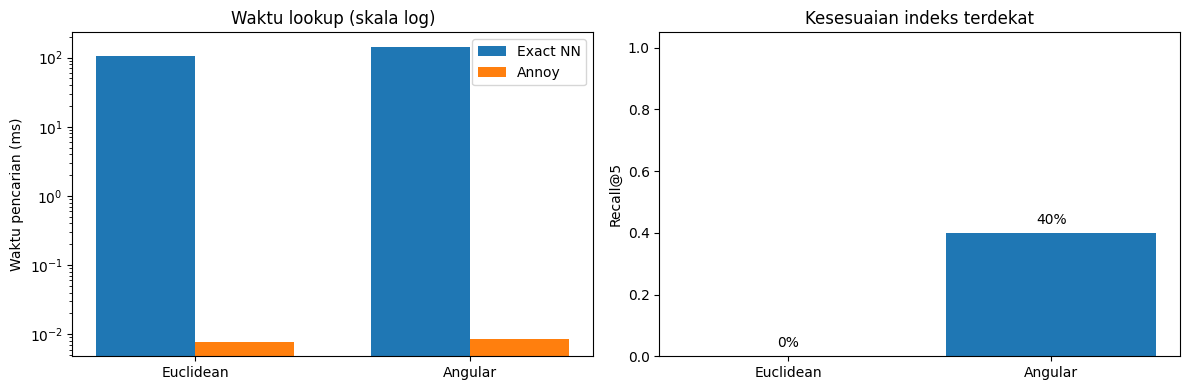

=== RINGKASAN HASIL SPOTIFY ===
Euclidean: exact 105.831 ms, annoy 0.008 ms, recall@5 0%, build 10.93 s.
Angular: exact 141.687 ms, annoy 0.009 ms, recall@5 40%, build 13.12 s.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xx = np.arange(len(df_spotify))
width = 0.36
axes[0].bar(xx - width / 2, df_spotify["Waktu Exact (ms)"], width,
            label="Exact NN")
axes[0].bar(xx + width / 2, df_spotify["Waktu Annoy (ms)"], width,
            label="Annoy")
axes[0].set_xticks(xx, df_spotify["Distance Metrics"])
axes[0].set_ylabel("Waktu pencarian (ms)")
axes[0].set_yscale("log")
axes[0].set_title("Waktu lookup (skala log)")
axes[0].legend()

axes[1].bar(df_spotify["Distance Metrics"], df_spotify["Recall@5"])
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Recall@5")
axes[1].set_title("Kesesuaian indeks terdekat")
for i, v in enumerate(df_spotify["Recall@5"]):
    axes[1].text(i, min(v + 0.03, 1.02), f"{v:.0%}", ha="center")
plt.tight_layout()
plt.show()

print("=== RINGKASAN HASIL SPOTIFY ===")
for _, r in df_spotify.iterrows():
    print(f"{r['Distance Metrics']}: exact {r['Waktu Exact (ms)']:.3f} ms, "
          f"annoy {r['Waktu Annoy (ms)']:.3f} ms, "
          f"recall@5 {r['Recall@5']:.0%}, "
          f"build {r['Build index (s)']:.2f} s.")

### 7. Jawaban pertanyaan: Kenapa waktu `build index` tidak dihitung?

Waktu `build index` **tidak dimasukkan ke waktu pencarian** karena pembuatan indeks Annoy adalah proses **offline / persiapan (indexing)**, sedangkan yang dibandingkan dengan Exact NN pada tabel adalah latensi **online / pencarian tetangga** setelah indeks tersedia. Dalam sistem rekomendasi, indeks dibangun dan kemudian dipakai untuk melayani banyak query, sehingga biaya build dapat ditanggung bersama (*amortized*) oleh banyak permintaan.

Namun, waktu build **tetap penting** saat mengevaluasi sistem secara menyeluruh. Karena itu, notebook ini mencatat waktu `add_item` dan `build` secara terpisah. Jika kebutuhan hanya **satu query**, biaya total Annoy ialah `add_item + build + lookup`, sehingga mungkin justru lebih mahal daripada brute force. Annoy menjadi menarik saat indeks **digunakan berulang kali** untuk banyak query.

**Hal yang perlu diamati:**

1. Penambahan jumlah tree umumnya membuat build lebih lama dan indeks lebih besar, namun dapat meningkatkan peluang mendapatkan tetangga yang benar.
2. Annoy bersifat *approximate*: indeks dan jarak yang ditemukan tidak selalu sama dengan Exact NN. Lihat **Recall@3** dan **Recall@5** sebagai pembanding kualitas.
3. Euclidean dan Angular mengurutkan tetangga dengan aturan jarak **berbeda**. Jangan membandingkan indeks Angular terhadap baseline Exact Euclidean.
4. Timing yang dilaporkan tergantung CPU, memori, dan kondisi runtime. Pengukuran beberapa kali lebih bermakna daripada satu angka waktu.
5. Saat query kebetulan dipilih dari dataset 2D, salah satu tetangga adalah dirinya sendiri, dan hasil *top-k* harus ditafsirkan dengan mempertimbangkan hal tersebut.

**Kesimpulan:** Exact NN menjamin hasil tepat karena menghitung jarak terhadap setiap item; Annoy memanfaatkan indeks untuk mempercepat lookup dengan kompromi terhadap akurasi. Keberhasilan pendekatan Annoy sebaiknya dinilai bersama **latensi pencarian, recall, waktu build, dan biaya memori**, bukan dari kecepatan lookup saja.

### 8. Simpan tabel hasil eksperimen

File CSV disimpan pada direktori runtime Colab. Jalankan kode berikut untuk menghasilkan tabel tugas jika ingin melampirkannya ke laporan.

In [10]:
df_2d.to_csv("JS06_Praktikum1_hasil_2D.csv", index=False)
df_spotify.to_csv("JS06_Praktikum1_hasil_Spotify.csv", index=False)
print("Tabel hasil 2D dan Spotify berhasil diekspor ke CSV.")

Tabel hasil 2D dan Spotify berhasil diekspor ke CSV.
